# 02 Model: from the accuracy trap to a review queue

**Step 4:** split by time and show the accuracy trap.
**Step 5:** weighted logistic regression, isolation forest and gradient boosting, compared on a validation period.
**Step 6:** final evaluation on the test period, with a threshold set by the team's review capacity.

In [1]:
import matplotlib.pyplot as plt

# One consistent, colour-blind-safe look for every chart in this project
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GREY, "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12,
    "axes.titlelocation": "left", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 10,
    "legend.frameon": False, "lines.linewidth": 2,
    "axes.prop_cycle": plt.cycler(color=[BLUE, ORANGE, AQUA, YELLOW]),
})

import numpy as np
import pandas as pd

df = pd.read_parquet("../data/processed/transactions_model.parquet")
FEATURES = ["hour", "is_transfer", "log_amount", "log_balance_before", "empties_account",
            "log_receiver_balance_before", "receiver_balance_zero"]

## 1. Split by time, not at random

A fraud model is always used on **future** transactions, so it must be tested that way. A random split would let the model learn from transactions that happened after the ones it is tested on, including the same fraudsters' later moves.

The 14 normal days are split in order:

- **Train:** the first 8 days. The models learn here.
- **Validation:** the next 2 days. Models are compared and chosen here.
- **Test:** the last 4 days. Used once, at the end, for the numbers reported to the business.

Choosing a model on the test set would quietly turn it into a second validation set, and the final scores would be optimistic.

In [2]:
days = sorted(df.day.unique())
train_days, val_days, test_days = days[:8], days[8:10], days[10:]
train, val, test = (df[df.day.isin(d)] for d in (train_days, val_days, test_days))
for name, part, d in [("Train", train, train_days), ("Validation", val, val_days), ("Test", test, test_days)]:
    print(f"{name:11s} days {d[0]:2d}-{d[-1]:2d}: {len(part):>9,} transactions, {part.is_fraud.sum():>5,} fraud")
X_train, y_train = train[FEATURES], train.is_fraud
X_val, y_val = val[FEATURES], val.is_fraud
X_test, y_test = test[FEATURES], test.is_fraud

Train       days  0-10: 1,568,556 transactions, 2,157 fraud
Validation  days 11-12:   337,997 transactions,   540 fraud
Test        days 13-16:   697,399 transactions, 1,068 fraud


## 2. Baseline 1: predict 'not fraud' for everything

In [3]:
from sklearn.metrics import accuracy_score, recall_score

none = np.zeros(len(y_test), dtype=int)
print(f"Accuracy {accuracy_score(y_test, none):.2%}  |  recall {recall_score(y_test, none):.0%}  |  "
      f"fraud let through: {test.loc[test.is_fraud == 1, 'amount'].sum() / 1e6:,.0f} million")

Accuracy 99.85%  |  recall 0%  |  fraud let through: 1,636 million


**99.85% accurate, and every single fraud gets through.** This is the accuracy trap, and it is why a fraud model is never judged on accuracy.

## 3. Baseline 2: the provider's existing rule

In [4]:
raw = pd.read_parquet("../data/raw/paysim.parquet", columns=["step", "type", "isFlaggedFraud", "isFraud"])
raw = raw[raw.type.isin(["TRANSFER", "CASH_OUT"]) & ((raw.step - 1) // 24).isin(test_days)]
print(f"Existing rule on the test days: flagged {raw.isFlaggedFraud.sum()}, "
      f"recall {recall_score(raw.isFraud, raw.isFlaggedFraud):.1%}")

Existing rule on the test days: flagged 1, recall 0.1%


The existing rule targets only giant transfers. Over the four test days it catches almost nothing. Any model has to beat both baselines on **recall at a workable number of flags**.

---
# Step 5: Models (compared on the validation days)

## 4. Logistic regression with class weights

With 0.14% fraud, an unweighted model can keep its error low by mostly ignoring fraud. `class_weight="balanced"` makes each fraud case count about 700 times more than a legitimate one during training, so the model has to pay attention to the minority.

(In the churn project I avoided class weights because I needed honest probabilities for expected loss. Here the scores are only used to **rank** a review queue, so inflated probabilities do no harm.)

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

def report(name, y, s):
    print(f"{name:32s} PR AUC {average_precision_score(y, s):.3f}   ROC AUC {roc_auc_score(y, s):.3f}")

logreg = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=2000))
logreg.fit(X_train, y_train)
report("Logistic regression (weighted)", y_val, logreg.predict_proba(X_val)[:, 1])

Logistic regression (weighted)   PR AUC 0.987   ROC AUC 1.000


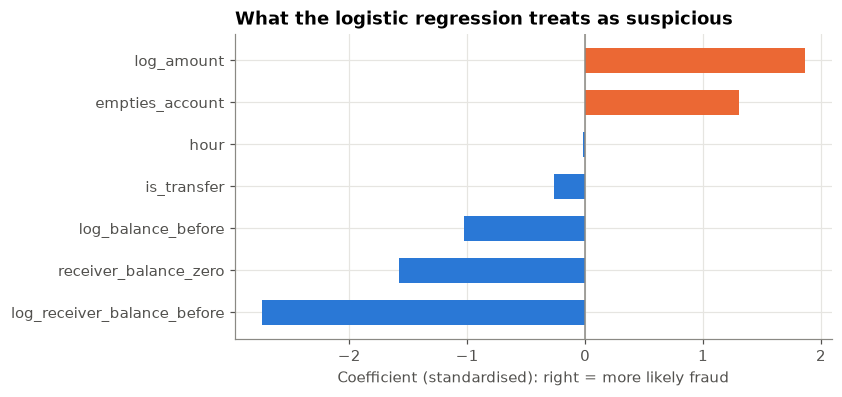

In [6]:
coefs = pd.Series(logreg[-1].coef_[0], index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(coefs.index, coefs.values, color=[ORANGE if v > 0 else BLUE for v in coefs.values], height=0.6)
ax.axvline(0, color=GREY, linewidth=1)
ax.set_xlabel("Coefficient (standardised): right = more likely fraud")
ax.set_title("What the logistic regression treats as suspicious")
fig.savefig("../figures/logreg_coefficients.png")
plt.show()

The model has learned the fraud signature from Step 3: **the full balance taken in one go** and **large amounts** push the score up; money going to a receiver who **already holds a large balance** pushes it down (fraudsters send money to fresh "mule" accounts they control).

## 5. Isolation forest: can we find fraud without labels?

Many providers have few confirmed fraud labels. An isolation forest is **unsupervised**: it never sees `is_fraud`. It learns what typical transactions look like and scores how easily each one can be separated from the rest. If fraud is unusual in the feature space, it should score high.

In [7]:
from sklearn.ensemble import IsolationForest

iso = IsolationForest(n_estimators=200, random_state=42, n_jobs=-1).fit(X_train.sample(200_000, random_state=42))
report("Isolation forest (no labels)", y_val, -iso.score_samples(X_val))  # higher = more unusual

Isolation forest (no labels)     PR AUC 0.362   ROC AUC 0.942


## 6. Gradient boosting

Fraud often depends on combinations: emptying the account matters most for a large transfer to an empty receiver. Gradient-boosted trees learn such interactions directly, and `HistGradientBoostingClassifier` is built for millions of rows.

In [8]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.1, random_state=42).fit(X_train, y_train)
report("Gradient boosting", y_val, hgb.predict_proba(X_val)[:, 1])

Gradient boosting                PR AUC 0.984   ROC AUC 0.998


In [9]:
val_scores = {"Logistic regression (weighted)": logreg.predict_proba(X_val)[:, 1],
              "Isolation forest (no labels)": -iso.score_samples(X_val),
              "Gradient boosting": hgb.predict_proba(X_val)[:, 1]}
comparison = pd.DataFrame({n: {"PR AUC": average_precision_score(y_val, s), "ROC AUC": roc_auc_score(y_val, s)}
                           for n, s in val_scores.items()}).T.round(3)
comparison

,PR AUC,ROC AUC
Logistic regression (weighted),0.987,1.000
Isolation forest (no labels),0.362,0.942
Gradient boosting,0.984,0.998


**Reading the table.** ROC AUC is high for every model, even the weak one, because it rewards ranking hundreds of thousands of easy legitimate transactions below fraud. PR AUC only looks at the flagged end of the list, where the fraud team actually works, so it separates the models much more clearly. On rare events, report PR AUC.

**Results.**
- The **isolation forest** finds some fraud with no labels at all, which is worth knowing when a provider has none, but it also flags many honest, unusual transactions (big legitimate payments). Unusual is not the same as fraudulent.
- The **weighted logistic regression** is the best ranker here, slightly ahead of gradient boosting. The fraud signature in this data is a handful of strong, almost separate signals, which a linear model captures well. A more complex model is not automatically a better one; it has to earn its place on validation data.

**Choice:** the weighted logistic regression goes forward. It is also the easiest to explain to a fraud manager and an auditor.